# 04 · 공정 시계열 데이터와 회귀 예측
### 실습으로 배우는 GMP AI — 강의 목차 ⑤ 공정 시계열 데이터와 회귀 예측

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/StillWork/GMPAI/blob/main/04_Process_TimeSeries_Features.ipynb)

| 항목 | 내용 |
|---|---|
| **학습 목표** | ① 배치 공정 시계열의 구조(**기동·정상·정지 구간**) ② **특성공학**: 시계열 → 배치당 숫자 특성 ③ 구간별 특성이 품질에 주는 정보 ④ 시계열 기반 회귀 예측과 한계 ⑤ 배치 길이가 다른 데이터 다루기 |
| **데이터** | 실제 타정기 공정 **10초 간격 센서 로그** (제품 17, 207배치, 약 84만 측정점 → 1분 평균으로 요약 제공) |
| **실행 환경** | CPU · 약 10분 |

> 연속 공정과 달리 **배치 공정은 길이가 제각각**입니다. AI 모델에 넣으려면 **고정 길이 특성 벡터**로 바꿔야 하는데,
> 이 **특성공학이 모델 성능을 좌우**합니다.

In [1]:
%pip install -q koreanize-matplotlib
import koreanize_matplotlib, os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")
REPO = "https://raw.githubusercontent.com/StillWork/GMPAI/main/data/"
def load_data(name, **kw):
    local = os.path.join("data", name)
    return pd.read_csv(local if os.path.exists(local) else REPO + name, **kw)

ts = load_data("tablet_timeseries_code17.csv.gz")          # 1분 평균 다운샘플
lab = load_data("tablet_batches.csv", parse_dates=["start_date"])
print("시계열:", ts.shape, "| 배치 수:", ts.batch.nunique())
print("변수:", [c for c in ts.columns if c not in ("batch", "minute")])
ts.head(3)

Note: you may need to restart the kernel to use updated packages.


시계열: (140715, 14) | 배치 수: 207
변수: ['tbl_speed', 'fom', 'main_comp', 'tbl_fill', 'SREL', 'pre_comp', 'produced', 'waste', 'cyl_main', 'cyl_pre', 'stiffness', 'ejection']


,batch,tbl_speed,fom,main_comp,tbl_fill,SREL,pre_comp,produced,waste,cyl_main,cyl_pre,stiffness,ejection,minute
0,191,0.0,0.0,0.0,5.77,0.0,0.0,0.0,0.0,2.1,6.0,0.0,0.0,0
1,191,0.0,0.0,0.0,5.77,0.0,0.0,0.0,0.0,2.1,6.0,0.0,0.0,1
2,191,0.0,0.0,0.0,5.77,0.0,0.0,0.0,0.0,2.1,6.0,0.0,0.0,2


## 1. 타정 공정 센서 변수의 의미
| 변수 | 의미 | 품질과의 관계 |
|---|---|---|
| `tbl_speed` | 타정 속도 (정/시간) | 빠르면 체류시간↓ → 경도·중량 변동 |
| `main_comp` | **주압축력** (kN) | 정제 경도·용출의 핵심 CPP |
| `pre_comp` | 예비압축력 | 공기 배출, 캡핑 방지 |
| `tbl_fill` | 충전 깊이 (mm) | 정제 **중량** 결정 |
| `SREL` | 중량 상대표준편차 (%) | **함량 균일성**의 직접 지표 |
| `stiffness` | 분말 강성 | 원료 특성 변화 감지 |
| `ejection` | 배출력 (N) | 윤활 상태, 다이 마모 |
| `produced` / `waste` | 생산량 / 폐기량 | 수율 |
| `fom`, `cyl_main`, `cyl_pre` | 설비 상태값 | 설비 모니터링 |

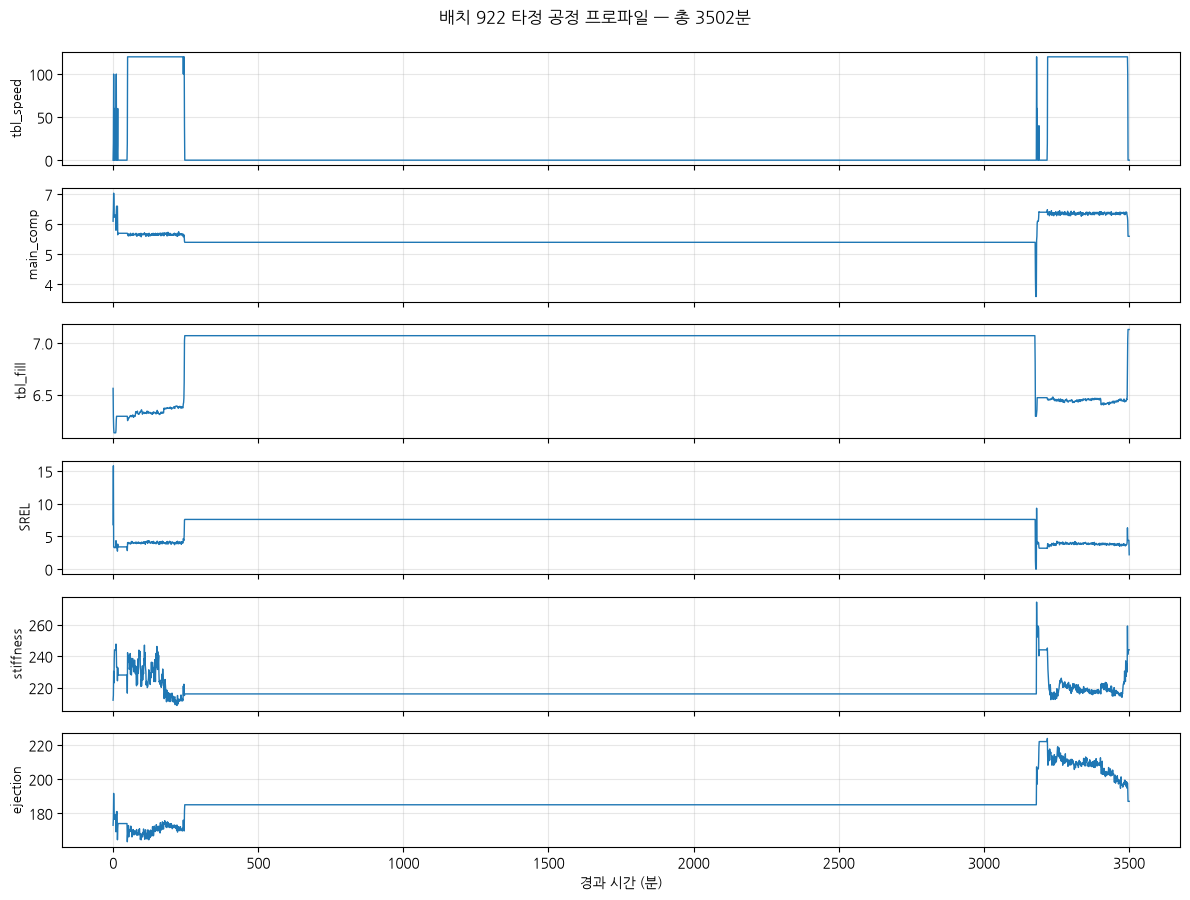

In [2]:
# 배치 하나의 공정 프로파일 — 10초 간격 로그를 1분 평균으로 본 모습
b = ts.batch.value_counts().index[5]
one = ts[ts.batch == b].sort_values("minute")
cols = ["tbl_speed", "main_comp", "tbl_fill", "SREL", "stiffness", "ejection"]
fig, ax = plt.subplots(len(cols), 1, figsize=(12, 9), sharex=True)
for a, c in zip(ax, cols):
    a.plot(one["minute"], one[c], lw=1)
    a.set_ylabel(c, fontsize=9); a.grid(alpha=0.3)
ax[-1].set_xlabel("경과 시간 (분)")
plt.suptitle(f"배치 {b} 타정 공정 프로파일 — 총 {len(one)}분", y=0.995); plt.tight_layout(); plt.show()

## 2. ⭐ 배치 공정의 구간 나누기 — 기동 / 정상 / 정지
배치 전체의 평균을 내면 **기동(start-up) 구간의 불안정**이 희석돼 버립니다.
실제로 품질 문제는 **기동 직후**나 **중단 후 재가동** 시점에 생기는 경우가 많습니다.
→ 타정 속도가 0 보다 큰 구간을 **생산 중**으로 보고, 앞부분 일정 비율을 **기동 구간**으로 정의합니다.

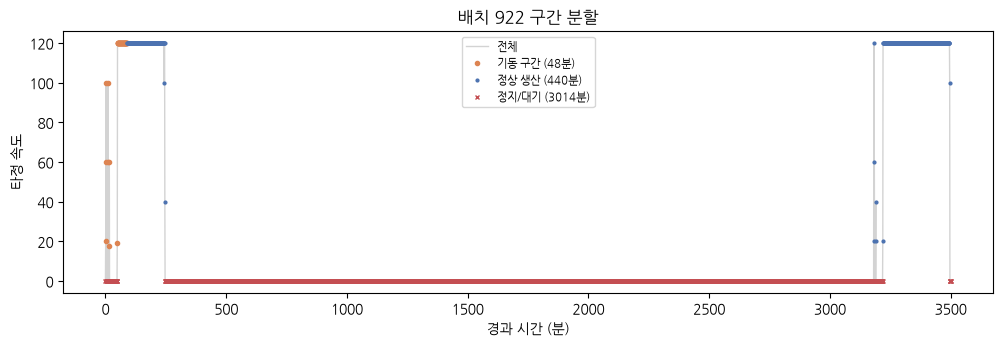

배치 길이: 최소 271분, 중앙값 535분, 최대 5070분 → 길이가 제각각!


In [3]:
RUN_SPEED = 1.0          # 타정 속도가 이 값보다 크면 '생산 중'

def segment(g, startup_frac=0.1):
    g = g.sort_values("minute")
    run = g[g["tbl_speed"] > RUN_SPEED]
    if len(run) < 10: return None, None, None
    n_start = max(3, int(len(run) * startup_frac))
    return run.iloc[:n_start], run.iloc[n_start:], g[g["tbl_speed"] <= RUN_SPEED]

g = ts[ts.batch == b]
st, steady, idle = segment(g)
plt.figure(figsize=(12, 3.4))
plt.plot(g["minute"], g["tbl_speed"], color="lightgray", lw=1, label="전체")
plt.plot(st["minute"], st["tbl_speed"], "o", ms=3, color="#DD8452", label=f"기동 구간 ({len(st)}분)")
plt.plot(steady["minute"], steady["tbl_speed"], "o", ms=2, color="#4C72B0", label=f"정상 생산 ({len(steady)}분)")
plt.plot(idle["minute"], idle["tbl_speed"], "x", ms=3, color="#C44E52", label=f"정지/대기 ({len(idle)}분)")
plt.ylabel("타정 속도"); plt.xlabel("경과 시간 (분)"); plt.legend(fontsize=8); plt.title(f"배치 {b} 구간 분할"); plt.show()

dur = ts.groupby("batch").size()
print(f"배치 길이: 최소 {dur.min()}분, 중앙값 {int(dur.median())}분, 최대 {dur.max()}분 → 길이가 제각각!")

## 3. ⭐ 특성공학 — 시계열을 배치당 고정 길이 벡터로
| 특성 유형 | 예 | 잡아내는 정보 |
|---|---|---|
| **기술통계** | 평균·표준편차·중앙값·최대·최소 | 공정의 수준과 변동 |
| **구간별 통계** | 기동 구간 평균, 정상 구간 평균, 둘의 차이 | 기동 안정성 |
| **추세** | 선형 회귀 기울기 | 드리프트(마모·막힘) |
| **변동성** | 1차 차분의 표준편차 | 미세 진동·불안정 |
| **이벤트** | 정지 횟수, 정지 시간, 속도 0 구간 | 중단·재가동 |
| **분포 형태** | 사분위수, 왜도 | 치우침 |

In [4]:
SENSORS = ["tbl_speed", "main_comp", "pre_comp", "tbl_fill", "SREL", "stiffness", "ejection", "fom", "cyl_main"]

def batch_features(g):
    st, steady, idle = segment(g)
    if st is None: return None
    f = {"duration_min": len(g), "run_min": len(st) + len(steady), "idle_min": len(idle),
         "n_stops": int((g["tbl_speed"].le(RUN_SPEED).astype(int).diff() == 1).sum())}
    for c in SENSORS:
        v, vs, vst = g[c].dropna(), steady[c].dropna(), st[c].dropna()
        if len(vs) < 5: continue
        f[f"{c}_mean"] = vs.mean()                                  # 정상 구간 평균
        f[f"{c}_std"] = vs.std()                                    # 정상 구간 변동
        f[f"{c}_range"] = vs.max() - vs.min()
        f[f"{c}_startup_mean"] = vst.mean()                         # 기동 구간 평균
        f[f"{c}_startup_gap"] = vst.mean() - vs.mean()              # 기동과 정상의 차이
        f[f"{c}_slope"] = np.polyfit(np.arange(len(vs)), vs.values, 1)[0] if len(vs) > 10 else 0   # 추세
        f[f"{c}_diff_std"] = vs.diff().std()                        # 미세 변동
    return f

rows = {}
for bid, g in ts.groupby("batch"):
    f = batch_features(g)
    if f: rows[bid] = f
F = pd.DataFrame(rows).T
print("배치당 특성 행렬:", F.shape, "(배치 수 × 특성 수)")
F.iloc[:3, :8].round(2)

배치당 특성 행렬: (207, 67) (배치 수 × 특성 수)


,duration_min,run_min,idle_min,n_stops,tbl_speed_mean,tbl_speed_std,tbl_speed_range,tbl_speed_startup_mean
191,661.0,578.0,83.0,10.0,98.97,8.31,83.33,84.84
192,620.0,571.0,49.0,5.0,99.58,5.54,83.33,94.54
193,542.0,480.0,62.0,7.0,119.23,7.79,110.92,107.62


In [5]:
# 품질 결과와 결합
data = F.join(lab.set_index("batch")[["dissolution_av", "dissolution_min", "impurities_total", "tbl_rsd_weight", "tbl_av_hardness", "start_date"]], how="inner")
data = data.sort_values("start_date")
print("모델링용 데이터:", data.shape)
print("기간:", data.start_date.min().date(), "~", data.start_date.max().date())

모델링용 데이터: (207, 73)
기간: 2019-04-01 ~ 2021-04-01


## 4. 시계열 특성과 품질의 관계 보기

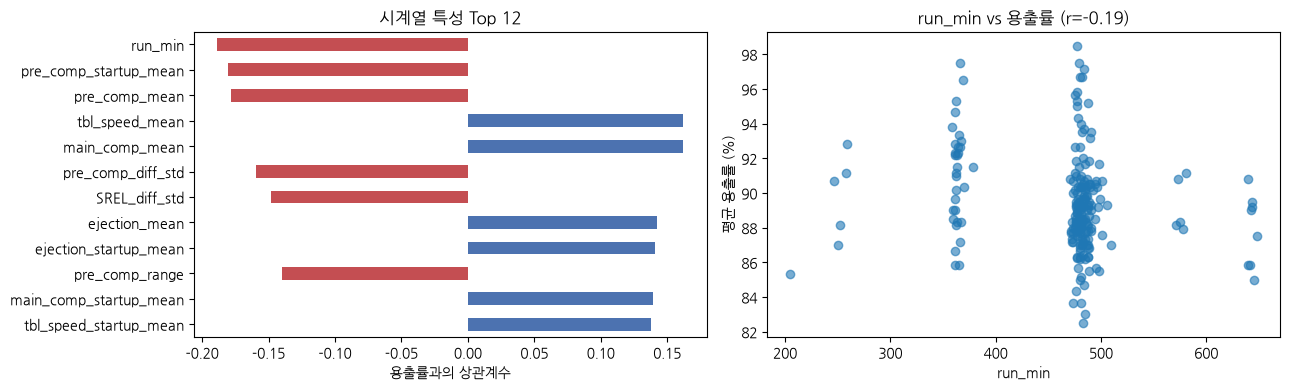

In [6]:
feat_cols = [c for c in F.columns]
corr = data[feat_cols + ["dissolution_av", "tbl_rsd_weight"]].corr(numeric_only=True)
top = corr["dissolution_av"].drop(["dissolution_av", "tbl_rsd_weight"]).dropna()
top = top.reindex(top.abs().sort_values(ascending=False).index).head(12)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
top[::-1].plot.barh(ax=ax[0], color=["#C44E52" if v < 0 else "#4C72B0" for v in top[::-1]])
ax[0].set_xlabel("용출률과의 상관계수"); ax[0].set_title("시계열 특성 Top 12")
best_f = top.index[0]
ax[1].scatter(data[best_f], data["dissolution_av"], alpha=0.6)
ax[1].set_xlabel(best_f); ax[1].set_ylabel("평균 용출률 (%)"); ax[1].set_title(f"{best_f} vs 용출률 (r={top.iloc[0]:.2f})")
plt.tight_layout(); plt.show()

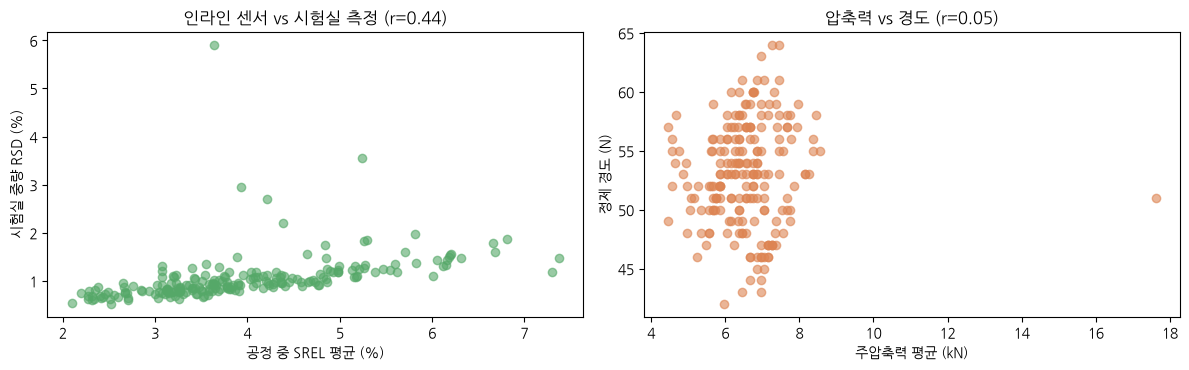

→ 인라인 센서가 시험실 결과를 잘 따라가면, 그 센서는 '소프트센서'(예제 09)의 입력이 될 수 있습니다.


In [7]:
# SREL(중량 RSD)은 공정 중 실시간으로 측정되는 '품질의 선행 지표'
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].scatter(data["SREL_mean"], data["tbl_rsd_weight"], alpha=0.6, color="#55A868")
ax[0].set_xlabel("공정 중 SREL 평균 (%)"); ax[0].set_ylabel("시험실 중량 RSD (%)")
ax[0].set_title(f"인라인 센서 vs 시험실 측정 (r={data['SREL_mean'].corr(data['tbl_rsd_weight']):.2f})")
ax[1].scatter(data["main_comp_mean"], data["tbl_av_hardness"], alpha=0.6, color="#DD8452")
ax[1].set_xlabel("주압축력 평균 (kN)"); ax[1].set_ylabel("정제 경도 (N)")
ax[1].set_title(f"압축력 vs 경도 (r={data['main_comp_mean'].corr(data['tbl_av_hardness']):.2f})")
plt.tight_layout(); plt.show()
print("→ 인라인 센서가 시험실 결과를 잘 따라가면, 그 센서는 '소프트센서'(예제 09)의 입력이 될 수 있습니다.")

## 5. 회귀 예측 — 시계열 특성으로 품질 예측하기
예제 02의 교훈대로 **시간 순 분할**로 평가합니다. 세 가지 목표를 비교합니다.

In [8]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.dummy import DummyRegressor

X = data[feat_cols].fillna(data[feat_cols].median())
cut = int(len(data) * 0.8); tr, te = np.arange(cut), np.arange(cut, len(data))
rows = []
for target in ["tbl_av_hardness", "tbl_rsd_weight", "dissolution_av"]:
    y = data[target].fillna(data[target].median()).values
    base = DummyRegressor().fit(X.iloc[tr], y[tr])
    rf = RandomForestRegressor(n_estimators=400, n_jobs=-1, random_state=0).fit(X.iloc[tr], y[tr])
    rows.append({"예측 대상": target, "기준선 R2": r2_score(y[te], base.predict(X.iloc[te])),
                 "랜덤포레스트 R2": r2_score(y[te], rf.predict(X.iloc[te])),
                 "MAE": mean_absolute_error(y[te], rf.predict(X.iloc[te])), "실제 표준편차": y[te].std()})
pd.DataFrame(rows).round(3)

,예측 대상,기준선 R2,랜덤포레스트 R2,MAE,실제 표준편차
0,tbl_av_hardness,-0.223,0.265,3.789,5.127
1,tbl_rsd_weight,-0.886,0.081,0.174,0.249
2,dissolution_av,-0.032,-0.225,2.112,2.509


> **읽는 법** (R² 는 1에 가까울수록 좋고, 음수면 평균 예측보다 못한 것)
> - **경도**: 압축력과 물리적으로 직결되어 **유일하게 의미 있는 예측력**을 보입니다 (R² ≈ 0.3)
> - **중량 RSD**: 약한 예측력 — 인라인 SREL 과 시험실 측정의 시점·표본이 달라서입니다
> - **용출률**: 예제 02와 마찬가지로 **예측 실패** — 타정 공정 데이터만으로는 부족하며, 과립 특성·원료 변동이 더 큰 요인입니다
>
> 👉 실무 전략: **예측이 되는 CQA 부터** 모델을 적용하고(예: 경도 → 공정 제어),
> 예측이 안 되는 CQA 는 **무엇을 더 측정해야 하는지**(PAT 도입, 예제 09)의 근거로 삼습니다.
> 성능이 낮은 모델을 억지로 쓰는 것보다, **한계를 문서화하는 것**이 규제 대응에서도 안전합니다.

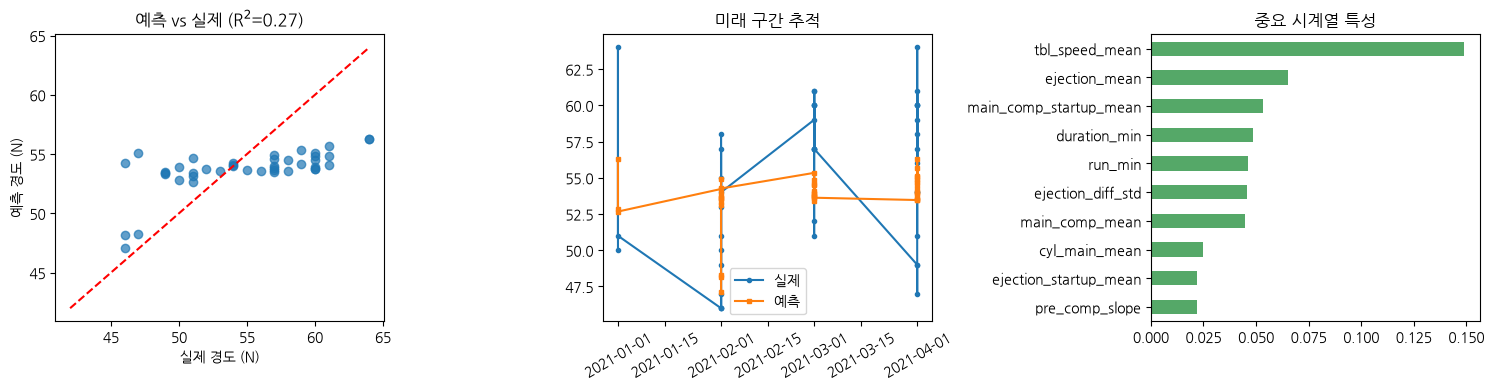

In [9]:
# 가장 잘 예측된 대상의 결과 자세히 보기
target = "tbl_av_hardness"
y = data[target].fillna(data[target].median()).values
rf = RandomForestRegressor(n_estimators=400, n_jobs=-1, random_state=0).fit(X.iloc[tr], y[tr])
pred = rf.predict(X.iloc[te])
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(y[te], pred, alpha=0.7); lim = [y.min(), y.max()]; ax[0].plot(lim, lim, "r--")
ax[0].set_xlabel("실제 경도 (N)"); ax[0].set_ylabel("예측 경도 (N)"); ax[0].set_title(f"예측 vs 실제 (R$^2$={r2_score(y[te], pred):.2f})")
ax[1].plot(data["start_date"].iloc[te], y[te], "o-", ms=3, label="실제")
ax[1].plot(data["start_date"].iloc[te], pred, "s-", ms=3, label="예측")
ax[1].legend(); ax[1].set_title("미래 구간 추적"); ax[1].tick_params(axis="x", rotation=30)
imp = pd.Series(rf.feature_importances_, index=feat_cols).sort_values().tail(10)
imp.plot.barh(ax=ax[2], color="#55A868"); ax[2].set_title("중요 시계열 특성")
plt.tight_layout(); plt.show()

## 6. 특성은 많을수록 좋은가? — 특성 세트 비교
"기동 구간·추세 특성을 더 뽑는 수고가 가치가 있는가"를 **실험으로 확인**합니다.

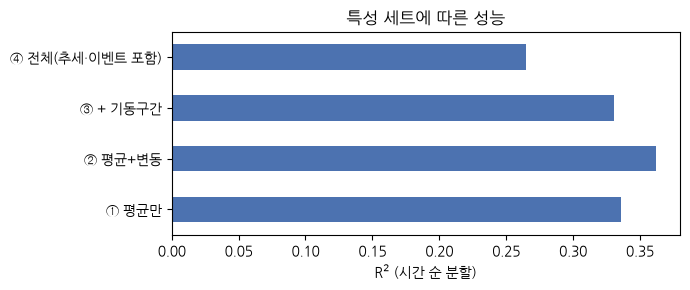

{'① 평균만': 0.336, '② 평균+변동': 0.362, '③ + 기동구간': 0.331, '④ 전체(추세·이벤트 포함)': 0.265}

→ 특성을 늘린다고 성능이 좋아지지 않습니다. 배치 207개에 특성 67개는 과다하여 오히려 과대적합됩니다.
   (샘플 수 대비 특성 수가 많으면 잡음을 학습합니다. 특성 선택·규제화·더 많은 배치 데이터가 필요합니다.)


In [10]:
sets = {
    "① 평균만": [c for c in feat_cols if c.endswith("_mean") and "startup" not in c],
    "② 평균+변동": [c for c in feat_cols if c.endswith(("_mean", "_std")) and "startup" not in c],
    "③ + 기동구간": [c for c in feat_cols if c.endswith(("_mean", "_std", "_startup_mean", "_startup_gap"))],
    "④ 전체(추세·이벤트 포함)": feat_cols,
}
y = data["tbl_av_hardness"].fillna(data["tbl_av_hardness"].median()).values
res = {}
for name, cols in sets.items():
    Xi = data[cols].fillna(data[cols].median())
    m = RandomForestRegressor(n_estimators=400, n_jobs=-1, random_state=0).fit(Xi.iloc[tr], y[tr])
    res[name] = r2_score(y[te], m.predict(Xi.iloc[te]))
pd.Series(res).plot.barh(figsize=(7, 3), color="#4C72B0")
plt.xlabel("R$^2$ (시간 순 분할)"); plt.title("특성 세트에 따른 성능"); plt.tight_layout(); plt.show()
print({k: round(v, 3) for k, v in res.items()})
print("\n→ 특성을 늘린다고 성능이 좋아지지 않습니다. 배치 207개에 특성 67개는 과다하여 오히려 과대적합됩니다.")
print("   (샘플 수 대비 특성 수가 많으면 잡음을 학습합니다. 특성 선택·규제화·더 많은 배치 데이터가 필요합니다.)")

## 7. 배치 길이가 다를 때의 대안
| 방법 | 설명 | 장단점 |
|---|---|---|
| **특성 요약** (이 노트북) | 통계량으로 고정 길이 벡터 | 간단·해석 쉬움, 시간 패턴 손실 |
| **구간 분할 요약** | 진행률 0~10%, 10~50%… 구간별 평균 | 공정 단계별 정보 보존 |
| **리샘플링/보간** | 진행률 기준 N 등분 (예: 100포인트) | 길이 통일, 딥러닝 입력에 적합 |
| **패딩 + 마스킹** | 최대 길이에 맞춰 0 채움 | LSTM/Transformer 표준 |
| **Dynamic Time Warping** | 시간 축을 늘려 정렬 | 속도 차이 흡수, 계산량 큼 |

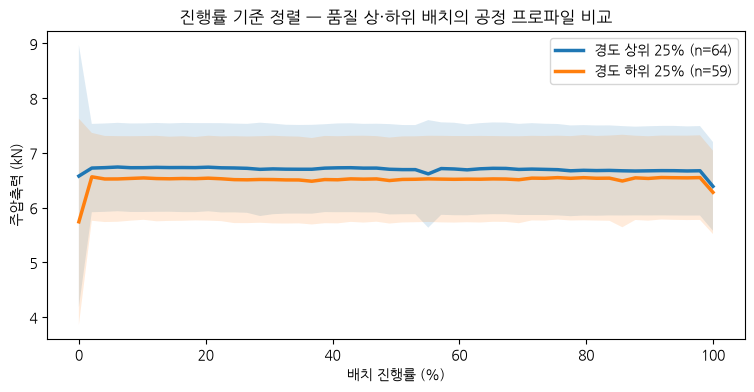

In [11]:
# 진행률 기준 리샘플링 — 배치 길이가 달라도 같은 모양으로 겹쳐 볼 수 있다
def resample_profile(g, col, n=50):
    v = g.sort_values("minute")[col].dropna().values
    if len(v) < 10: return None
    return np.interp(np.linspace(0, 1, n), np.linspace(0, 1, len(v)), v)

prof, qual = [], []
for bid, g in ts.groupby("batch"):
    r = resample_profile(g[g.tbl_speed > RUN_SPEED], "main_comp")
    if r is not None and bid in data.index:
        prof.append(r); qual.append(data.loc[bid, "tbl_av_hardness"])
prof, qual = np.array(prof), np.array(qual)
hi, lo = qual >= np.nanpercentile(qual, 75), qual <= np.nanpercentile(qual, 25)
plt.figure(figsize=(9, 4))
plt.plot(np.linspace(0, 100, 50), prof[hi].mean(0), lw=2.5, label=f"경도 상위 25% (n={hi.sum()})")
plt.plot(np.linspace(0, 100, 50), prof[lo].mean(0), lw=2.5, label=f"경도 하위 25% (n={lo.sum()})")
plt.fill_between(np.linspace(0, 100, 50), prof[hi].mean(0) - prof[hi].std(0), prof[hi].mean(0) + prof[hi].std(0), alpha=0.15)
plt.fill_between(np.linspace(0, 100, 50), prof[lo].mean(0) - prof[lo].std(0), prof[lo].mean(0) + prof[lo].std(0), alpha=0.15)
plt.xlabel("배치 진행률 (%)"); plt.ylabel("주압축력 (kN)"); plt.legend()
plt.title("진행률 기준 정렬 — 품질 상·하위 배치의 공정 프로파일 비교"); plt.show()

## 🧪 LLM 코딩 과제
```
ts 데이터프레임(열: batch, minute, tbl_speed, main_comp, tbl_fill, SREL, stiffness, ejection)이 있어.
각 배치에 대해 SREL(중량 RSD)의 최댓값, 95퍼센타일, 그리고 SREL이 1.5를 넘은 시간(분)을 계산해서
배치별 특성 데이터프레임으로 만들어줘. 그리고 그 값들의 분포를 히스토그램으로 그려줘. 한글 주석을 달아줘.
```

In [12]:
# ✏️ LLM 코딩 과제 코드 붙여넣기

## ✅ 정리
| 개념 | 핵심 |
|---|---|
| 배치 시계열 | 길이가 제각각 → **고정 길이 특성 벡터**로 변환 필요 |
| 구간 분할 | 기동/정상/정지를 나눠야 기동 불안정이 희석되지 않음 |
| 특성공학 | 평균뿐 아니라 **변동·추세·기동차이·정지횟수**가 정보를 담는다 |
| 예측 가능성 | 물리적으로 직결된 CQA(경도)만 예측 가능, 용출률은 실패 — **데이터에 없는 신호는 만들 수 없다** |
| 특성 수 | 많다고 좋지 않음. 배치 수가 적으면 특성을 줄여야 한다 |
| 리샘플링 | 진행률 기준 정렬로 배치 간 프로파일 비교·딥러닝 입력 생성 |

➡️ **다음 예제 05**: 이 특성들로 **OOS 를 조기 경보**하고, **비용 기반으로 경보 기준**을 정합니다